# Construção de grafos dependenciais conforme o modelo UD



### Tarefa 1
Seguindo o modelo do slide 14 ou slide 16 da minha apresentação sobre UD, desenhe o grafo dependencial da sentença "Ele tem o livro.", adaptação do exemplo em alemão de Kern (1883, p. 17).

### Tarefa 2
Faça o mesmo para a sentença "Quando ela então estava ali em seu novo esplendor, os pardais vieram novamente procurar suas antigas moradas.", baseado no exemplo em alemão de Dittrich (1902, p. 117).

### Tarefa 3
Construa a representação das duas sentenças no formato CoNNL-U, limitando-se ao preenchimento das seguintes colunas: ID, FORM, UPOS, HEAD e DEPREL. O arquivo exemplos.conllu com as duas sentenças, porém, deverá ser válido conforme as regras de UD. Para tal, execute o validador de UD sobre o arquivo.


In [5]:

conllu = """# sent_id = 1
# text = Ele tem o livro.
1	Ele	_	PRON	_	_	2	nsubj	_	_
2	tem	_	VERB	_	_	0	root	_	_
3	o	_	DET	_	_	4	det	_	_
4	livro	_	NOUN	_	_	2	obj	_	SpaceAfter=No
5	.	_	PUNCT	_	_	2	punct	_	_

# sent_id = 2
# text = Quando ela então estava ali em seu novo esplendor, os pardais vieram novamente procurar suas antigas moradas.
1	Quando	_	SCONJ	_	_	5	mark	_	_
2	ela	_	PRON	_	_	5	nsubj	_	_
3	então	_	ADV	_	_	5	advmod	_	_
4	estava	_	AUX	_	_	5	cop	_	_
5	ali	_	ADV	_	_	13	advcl	_	_
6	em	_	ADP	_	_	9	case	_	_
7	seu	_	DET	_	_	9	det	_	_
8	novo	_	ADJ	_	_	9	amod	_	_
9	esplendor	_	NOUN	_	_	5	obl	_	SpaceAfter=No
10	,	_	PUNCT	_	_	13	punct	_	_
11	os	_	DET	_	_	12	det	_	_
12	pardais	_	NOUN	_	_	13	nsubj	_	_
13	vieram	_	VERB	_	_	0	root	_	_
14	novamente	_	ADV	_	_	13	advmod	_	_
15	procurar	_	VERB	_	_	13	xcomp	_	_
16	suas	_	DET	_	_	18	det	_	_
17	antigas	_	ADJ	_	_	18	amod	_	_
18	moradas	_	NOUN	_	_	15	obj	_	SpaceAfter=No
19	.	_	PUNCT	_	_	13	punct	_	_

"""

with open("exemplos.conllu", "w", encoding="utf-8", newline="\n") as f:
    f.write(conllu)

print("Arquivo exemplos.conllu criado.")


Arquivo exemplos.conllu criado.


Cloning into 'tools'...
remote: Enumerating objects: 84209, done.
remote: Counting objects: 100% (218/218), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 84209 (delta 158), reused 134 (delta 76), pack-reused 83991 (from 3)
Receiving objects: 100% (84209/84209), 42.70 MiB | 14.75 MiB/s, done.
Resolving deltas: 100% (62219/62219), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [udapi]


In [2]:

!python tools/validate.py --lang pt --level 2 --max-err=0 exemplos.conllu


*** PASSED ***


### Tarefa 4
Construa os gráficos das duas sentenças nestes visualizadores:

https://urd2.let.rug.nl/~kleiweg/conllu/

https://universaldependencies.org/conllu_viewer.html

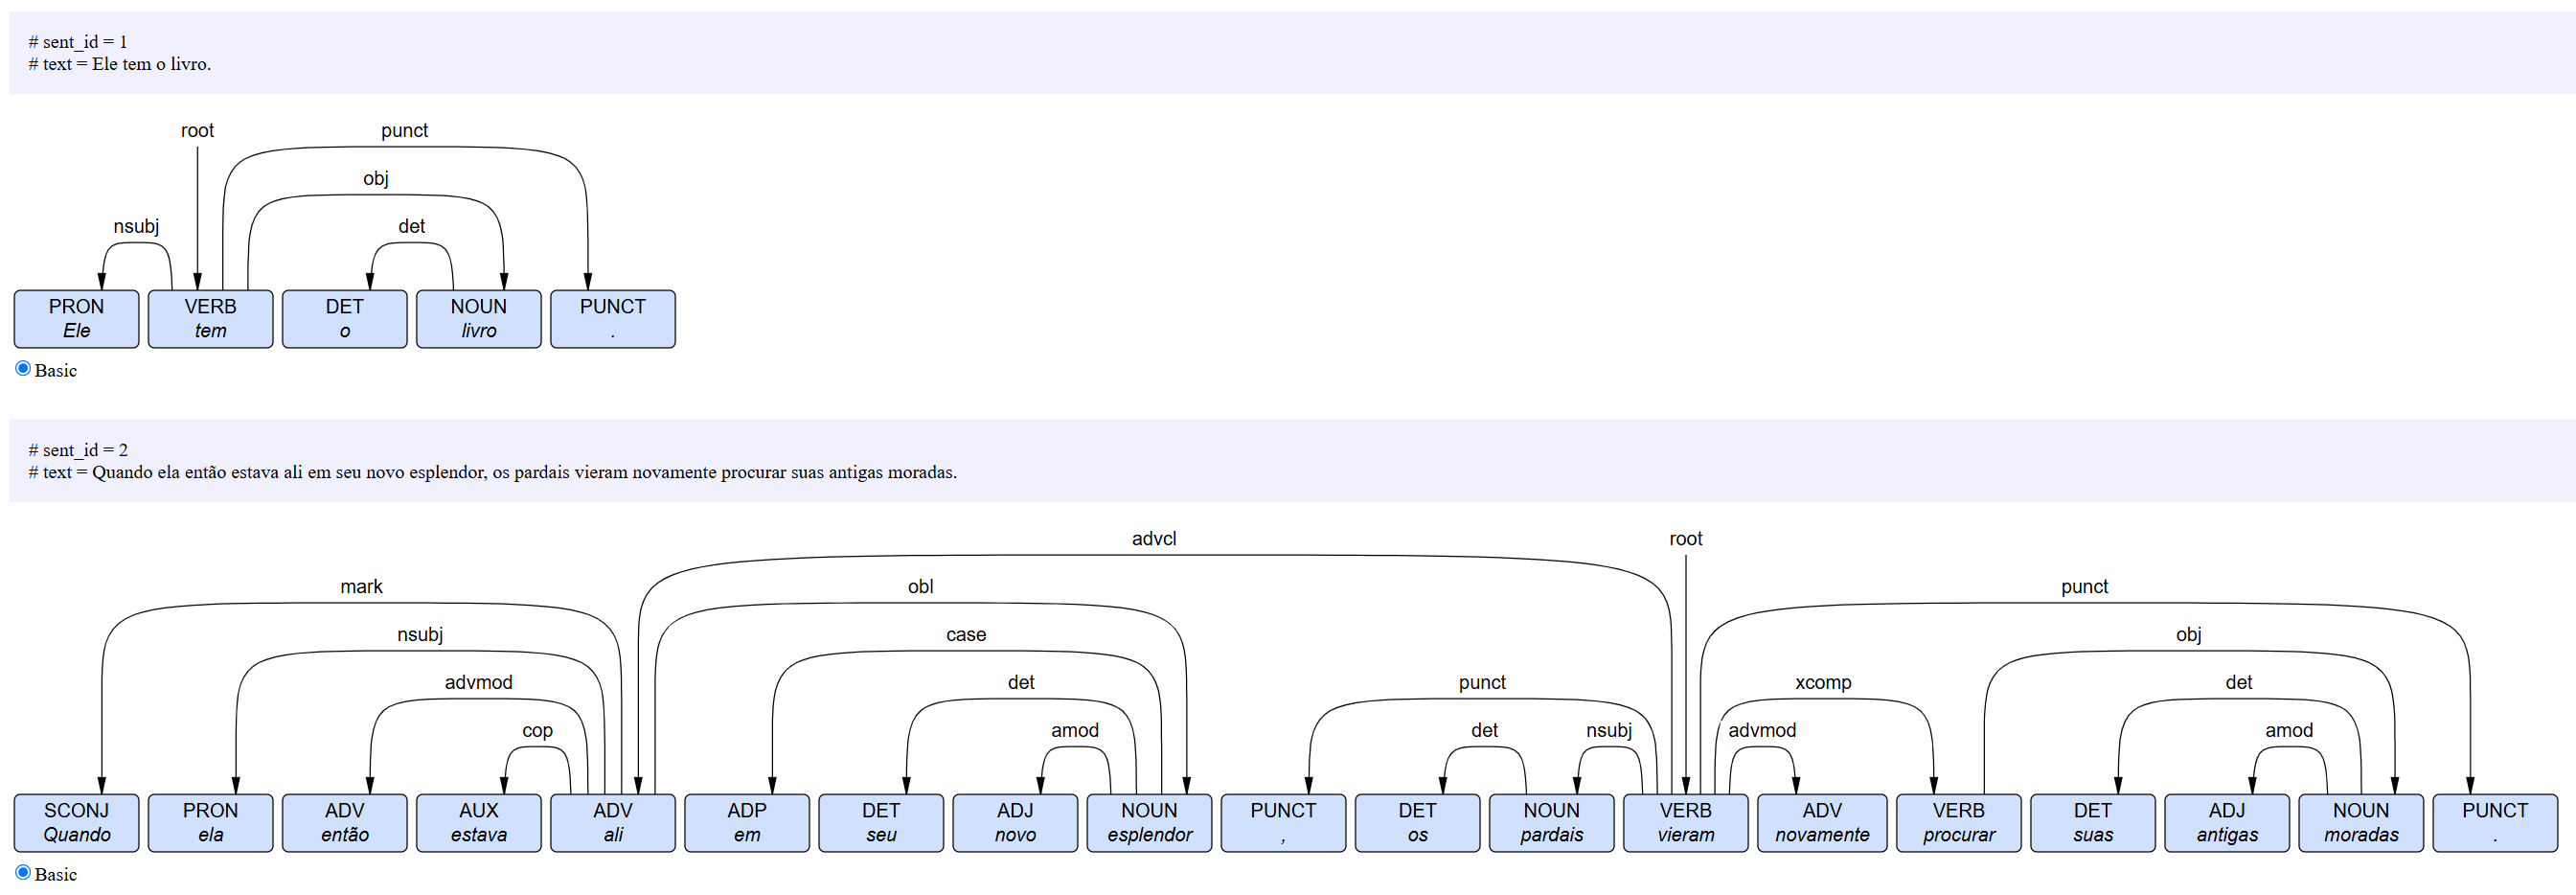

### Tarefa 5
Construa o gráfico por meio deste script em Python:

https://github.com/CompLin/nheengatu/blob/main/src/DepTree.py


In [6]:

!pip -q install conllu graphviz pillow
!apt-get -qq install graphviz

import urllib.request
import sys
import types

url = "https://raw.githubusercontent.com/CompLin/nheengatu/main/src/DepTree.py"
urllib.request.urlretrieve(url, "DepTree.py")

# DisplayPDF is only needed for PDF output.
pdf_module = types.ModuleType("DisplayPDF")
pdf_module.display_pdf_as_image = lambda *args, **kwargs: None
sys.modules["DisplayPDF"] = pdf_module

import DepTree
from IPython.display import Image, display


Dependency tree saved as 'sentence1_deptree.png' and displayed.


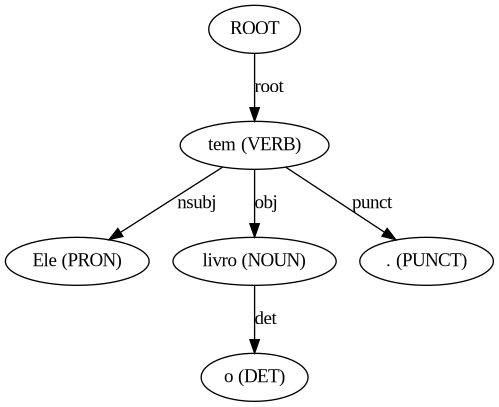

Dependency tree saved as 'sentence2_deptree.png' and displayed.


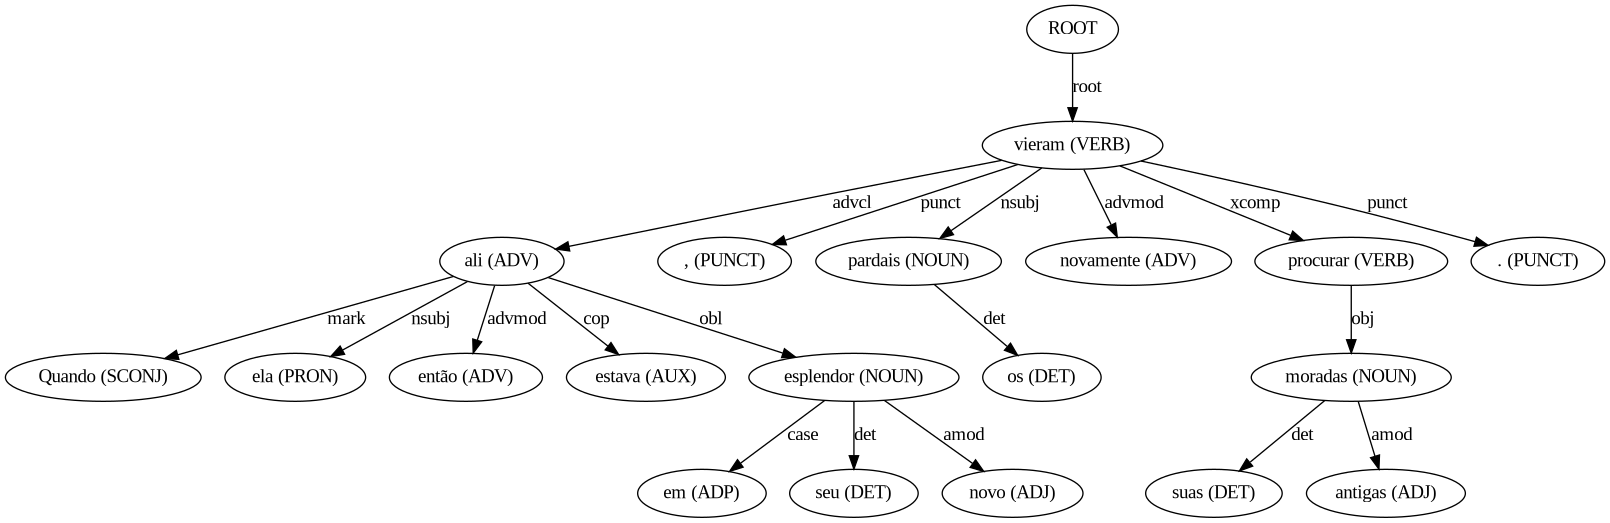

In [7]:

# Read the CoNLL-U file created in the previous section
with open("exemplos.conllu", "r", encoding="utf-8") as f:
    conllu_text = f.read()

# Separate the two sentences
sentences = [
    s.strip() + "\n\n"
    for s in conllu_text.strip().split("\n\n")
]

for i, sentence in enumerate(sentences, start=1):
    DepTree.displayTree(
        conllu_text=sentence,
        output_base_name=f"sentence{i}_deptree",
        display=False,
        file_format="png",
        cleanup=False
    )

    display(Image(filename=f"sentence{i}_deptree.png"))


### Tarefa 6
Desenhe ou construa por meio de alguma ferramenta os gráficos dependenciais das sentenças (1a-d) de Sandalo e Galves (2025, p. 3), seguindo um dos modelos da tarefa 1 acima.

(1a) Goti yemaa Ecode

Goti 3SUBJ-love Ecode

‘Goti loves Ecode / Ecode loves Goti’

(1b) Goti akaami Gademaani

Goti 2PRO 2PLOBJ-INV-love-2OBJPL

‘Goti loves you’

(1c) ee akaami Gademaani

1PRO 2PRO 2PLOBJ-INV-love-2OBJPL

‘I love you’

(1d) akaami ee ademaani

2PRO 1PRO 2SUBJ-INV-love-2SUBJPL

‘You love me’

In [8]:

kadiweu_conllu = """# sent_id = kadiweu-1a
# text = Goti yemaa Ecode
1	Goti	_	PROPN	_	_	2	nsubj	_	_
2	yemaa	_	VERB	_	_	0	root	_	_
3	Ecode	_	PROPN	_	_	2	obj	_	_

# sent_id = kadiweu-1b
# text = Goti akaami Gademaani
1	Goti	_	PROPN	_	_	3	nsubj	_	_
2	akaami	_	PRON	_	_	3	obj	_	_
3	Gademaani	_	VERB	_	_	0	root	_	_

# sent_id = kadiweu-1c
# text = ee akaami Gademaani
1	ee	_	PRON	_	_	3	nsubj	_	_
2	akaami	_	PRON	_	_	3	obj	_	_
3	Gademaani	_	VERB	_	_	0	root	_	_

# sent_id = kadiweu-1d
# text = akaami ee ademaani
1	akaami	_	PRON	_	_	3	nsubj	_	_
2	ee	_	PRON	_	_	3	obj	_	_
3	ademaani	_	VERB	_	_	0	root	_	_

"""

with open("kadiweu.conllu", "w", encoding="utf-8") as f:
    f.write(kadiweu_conllu)


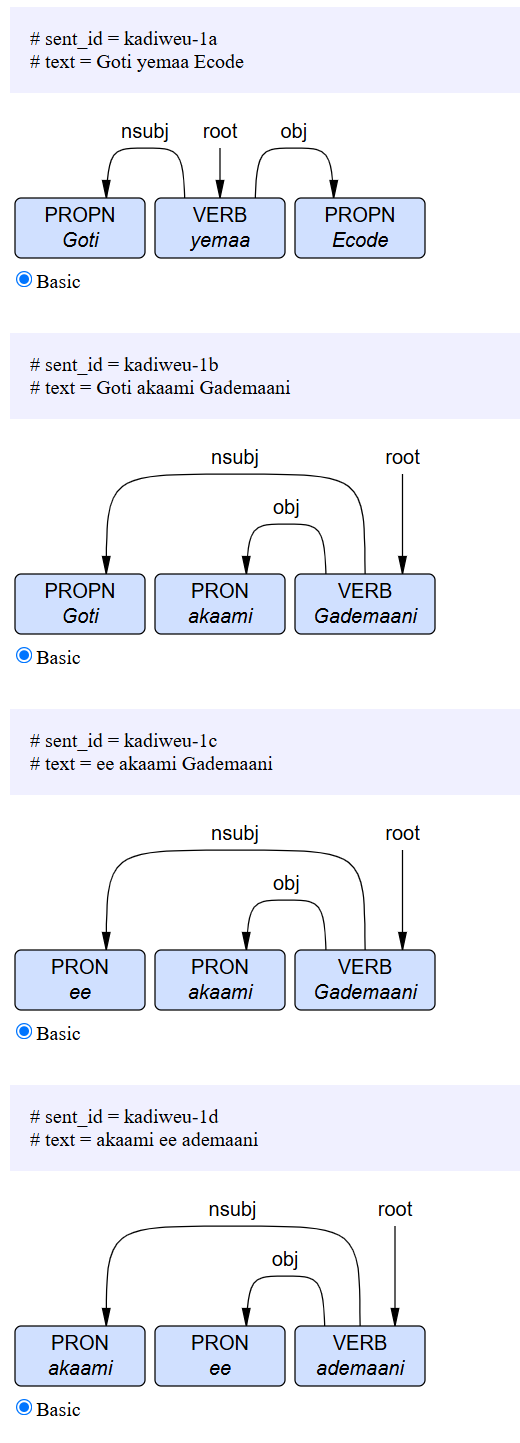